In [3]:
# 01. Import libraries
print("🔄 Importation des bibliothèques...")
import time
start = time.time()

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix,
    precision_recall_curve, average_precision_score,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')

print(f"✅ Tous les imports OK en {time.time()-start:.1f} secondes")
print(f"   - Pandas: {pd.__version__}")
print(f"   - Scikit-learn: {sklearn.__version__}")

🔄 Importation des bibliothèques...
✅ Tous les imports OK en 0.0 secondes
   - Pandas: 2.2.2
   - Scikit-learn: 1.6.1


In [4]:
# 02. Load dataset
from google.colab import files

print("📤 Veuillez sélectionner le fichier 'healthcare-dataset-stroke-data.csv'")
uploaded = files.upload()

# Récupérer le nom du fichier
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print(f"\n✅ Dataset chargé : {df.shape[0]} lignes, {df.shape[1]} colonnes")
print("\n📊 Aperçu des données :")
df.head()

📤 Veuillez sélectionner le fichier 'healthcare-dataset-stroke-data.csv'


Saving archive.zip to archive.zip

✅ Dataset chargé : 5110 lignes, 12 colonnes

📊 Aperçu des données :


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [5]:
# 03. Dataset description
print("="*60)
print("📊 DESCRIPTION DU DATASET")
print("="*60)

print("\n📋 Informations générales :")
df.info()

print("\n📈 Statistiques descriptives :")
df.describe()

print("\n🎯 Distribution de la cible 'stroke' :")
print(df['stroke'].value_counts())
print(f"\nProportion d'AVC : {df['stroke'].mean():.2%}")
print(f"Proportion de non-AVC : {1 - df['stroke'].mean():.2%}")

📊 DESCRIPTION DU DATASET

📋 Informations générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB

📈 Statistiques descriptives :

🎯 Distribution de la cible 'stroke' :
stroke
0    4861
1     249
Name: c

📊 ANALYSE EXPLORATOIRE


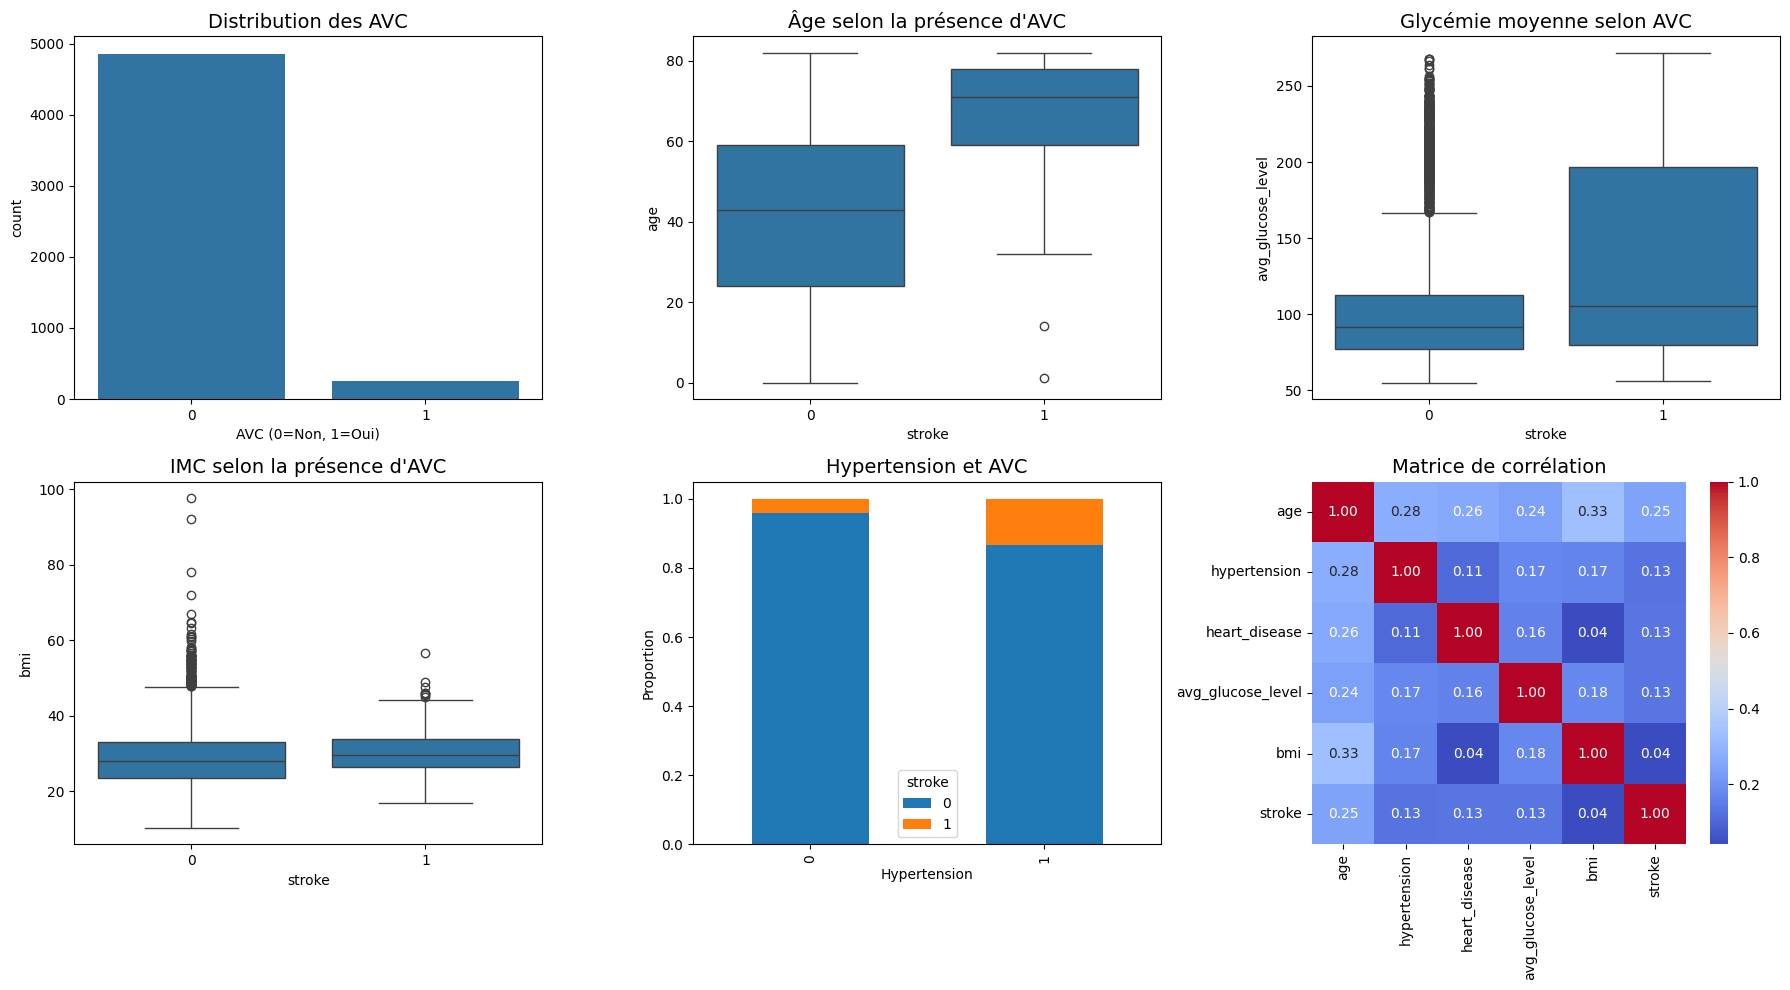


📝 COMMENTAIRES :
- Les patients ayant fait un AVC sont en moyenne plus âgés
- La glycémie moyenne est plus élevée chez les patients AVC
- Les hypertendus ont une proportion plus élevée d'AVC
- Corrélation modérée entre âge et AVC


In [6]:
# 04. Exploratory Data Analysis
print("="*60)
print("📊 ANALYSE EXPLORATOIRE")
print("="*60)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Distribution de la cible
sns.countplot(x='stroke', data=df, ax=axes[0,0])
axes[0,0].set_title('Distribution des AVC', fontsize=14)
axes[0,0].set_xlabel('AVC (0=Non, 1=Oui)')

# 2. Âge selon stroke
sns.boxplot(x='stroke', y='age', data=df, ax=axes[0,1])
axes[0,1].set_title('Âge selon la présence d\'AVC', fontsize=14)

# 3. Glycémie selon stroke
sns.boxplot(x='stroke', y='avg_glucose_level', data=df, ax=axes[0,2])
axes[0,2].set_title('Glycémie moyenne selon AVC', fontsize=14)

# 4. IMC selon stroke
sns.boxplot(x='stroke', y='bmi', data=df, ax=axes[1,0])
axes[1,0].set_title('IMC selon la présence d\'AVC', fontsize=14)

# 5. Hypertension vs AVC
pd.crosstab(df['hypertension'], df['stroke'], normalize='index').plot(kind='bar', ax=axes[1,1], stacked=True)
axes[1,1].set_title('Hypertension et AVC', fontsize=14)
axes[1,1].set_xlabel('Hypertension')
axes[1,1].set_ylabel('Proportion')

# 6. Matrice de corrélation
corr = df[['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1,2])
axes[1,2].set_title('Matrice de corrélation', fontsize=14)

plt.tight_layout()
plt.show()

print("\n📝 COMMENTAIRES :")
print("- Les patients ayant fait un AVC sont en moyenne plus âgés")
print("- La glycémie moyenne est plus élevée chez les patients AVC")
print("- Les hypertendus ont une proportion plus élevée d'AVC")
print("- Corrélation modérée entre âge et AVC")

In [7]:
# 05. Data Quality and Cleaning
print("="*60)
print("🧹 NETTOYAGE DES DONNÉES")
print("="*60)

print("\n🔍 Valeurs manquantes avant traitement :")
print(df.isnull().sum())

# Suppression de l'ID
df_clean = df.drop('id', axis=1)

# Imputation du BMI
print("\n📊 Imputation du BMI...")
df_clean['bmi'] = df_clean['bmi'].fillna(df_clean['bmi'].median())
print(f"✅ BMI imputé avec la médiane: {df_clean['bmi'].median():.1f}")

print(f"\n✅ Valeurs manquantes après imputation : {df_clean.isnull().sum().sum()}")

# Doublons
print(f"\n📋 Doublons : {df_clean.duplicated().sum()}")

print("\n✅ Nettoyage terminé")
df_clean.head()

🧹 NETTOYAGE DES DONNÉES

🔍 Valeurs manquantes avant traitement :
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

📊 Imputation du BMI...
✅ BMI imputé avec la médiane: 28.1

✅ Valeurs manquantes après imputation : 0

📋 Doublons : 0

✅ Nettoyage terminé


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [8]:
# 06. Preprocessing
print("="*60)
print("⚙️ PRÉTRAITEMENT")
print("="*60)

# Variables dérivées
df_prep = df_clean.copy()

df_prep['age_group'] = pd.cut(df_prep['age'],
                               bins=[0, 30, 50, 65, 120],
                               labels=['jeune', 'adulte', 'senior', 'très_senior'])

df_prep['glucose_category'] = pd.cut(df_prep['avg_glucose_level'],
                                      bins=[0, 100, 126, 200, 500],
                                      labels=['normal', 'pré-diabète', 'diabète', 'très_élevé'])

df_prep['has_hypertension_or_heart'] = (df_prep['hypertension'] + df_prep['heart_disease']) > 0

print("✅ Variables dérivées créées")

# Séparation X et y
X = df_prep.drop('stroke', axis=1)
y = df_prep['stroke']

# Split stratifié
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\n📊 X shape: {X.shape}, y shape: {y.shape}")
print(f"\n📈 Distribution AVC dans le train : {y_train.mean():.2%}")
print(f"📈 Distribution AVC dans le test : {y_test.mean():.2%}")

# Colonnes pour le pipeline
numeric_cols = ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease']
categorical_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
binary_cols = ['has_hypertension_or_heart']

print(f"\n✅ {len(numeric_cols)} variables numériques")
print(f"✅ {len(categorical_cols)} variables catégorielles")
print(f"✅ {len(binary_cols)} variables binaires")

# Pipeline
numeric_pipeline = Pipeline([
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_cols),
    ('cat', categorical_pipeline, categorical_cols),
    ('bin', 'passthrough', binary_cols)
])

print("\n✅ Pipeline construit avec succès")

⚙️ PRÉTRAITEMENT
✅ Variables dérivées créées

📊 X shape: (5110, 13), y shape: (5110,)

📈 Distribution AVC dans le train : 4.87%
📈 Distribution AVC dans le test : 4.89%

✅ 5 variables numériques
✅ 5 variables catégorielles
✅ 1 variables binaires

✅ Pipeline construit avec succès


In [9]:
# 07. Modeling
print("="*60)
print("🤖 MODÉLISATION")
print("="*60)

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', random_state=42, max_iter=500),
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=42, n_estimators=50, max_depth=10),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42, n_estimators=50, max_depth=5)
}

results = {}
best_auc = 0
best_name = ""

for name, model in models.items():
    print(f"\n🔄 Entraînement de {name}...")
    start_time = time.time()

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    recall = recall_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba)

    print(f"  Recall: {recall:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  F1-Score: {f1:.4f}")
    print(f"  ROC-AUC: {roc_auc:.4f}")
    print(f"  ⏱️ Temps: {time.time()-start_time:.1f}s")

    results[name] = {
        'pipeline': pipeline,
        'y_pred': y_pred,
        'y_proba': y_proba,
        'recall': recall,
        'precision': precision,
        'f1': f1,
        'roc_auc': roc_auc
    }

    if roc_auc > best_auc:
        best_auc = roc_auc
        best_name = name

print(f"\n🏆 Meilleur modèle : {best_name} avec ROC-AUC = {best_auc:.4f}")

🤖 MODÉLISATION

🔄 Entraînement de Logistic Regression...
  Recall: 0.8000
  Precision: 0.1384
  F1-Score: 0.2360
  ROC-AUC: 0.8441
  ⏱️ Temps: 0.1s

🔄 Entraînement de Random Forest...
  Recall: 0.1600
  Precision: 0.2051
  F1-Score: 0.1798
  ROC-AUC: 0.8265
  ⏱️ Temps: 0.3s

🔄 Entraînement de Gradient Boosting...
  Recall: 0.0400
  Precision: 0.3333
  F1-Score: 0.0714
  ROC-AUC: 0.8223
  ⏱️ Temps: 0.7s

🏆 Meilleur modèle : Logistic Regression avec ROC-AUC = 0.8441


📊 ÉVALUATION


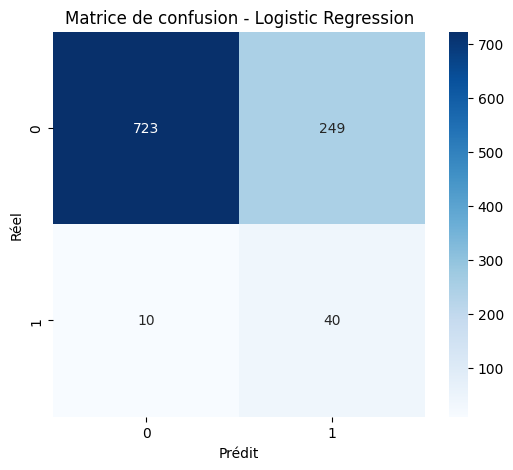

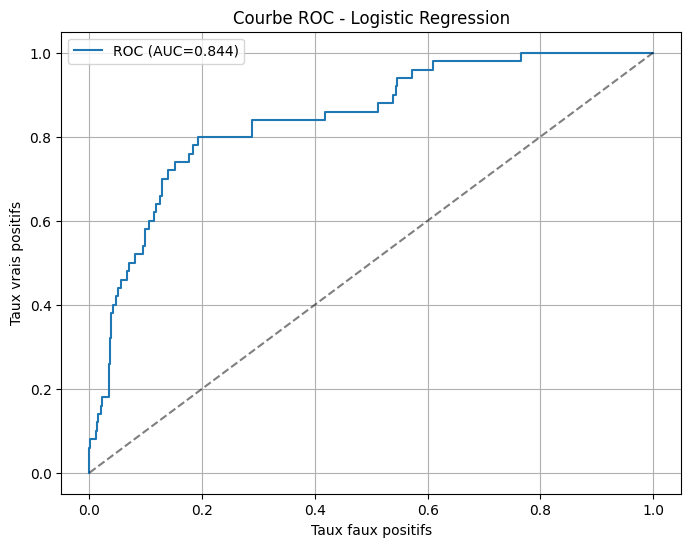


📋 Rapport de classification :
              precision    recall  f1-score   support

     Non-AVC       0.99      0.74      0.85       972
         AVC       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.75      0.82      1022


📊 Comparaison des modèles :
------------------------------------------------------------
Modèle                    Recall     Precision    F1         ROC-AUC   
------------------------------------------------------------
Logistic Regression       0.8000     0.1384       0.2360     0.8441    
Random Forest             0.1600     0.2051       0.1798     0.8265    
Gradient Boosting         0.0400     0.3333       0.0714     0.8223    


In [10]:
# 08. Evaluation
print("="*60)
print("📊 ÉVALUATION")
print("="*60)

# Meilleur modèle
best_pipeline = results[best_name]['pipeline']
y_pred_best = results[best_name]['y_pred']
y_proba_best = results[best_name]['y_proba']

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Matrice de confusion - {best_name}')
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.show()

# Courbe ROC
fpr, tpr, _ = roc_curve(y_test, y_proba_best)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'ROC (AUC={results[best_name]["roc_auc"]:.3f})')
plt.plot([0,1], [0,1], 'k--', alpha=0.5)
plt.xlabel('Taux faux positifs')
plt.ylabel('Taux vrais positifs')
plt.title(f'Courbe ROC - {best_name}')
plt.legend()
plt.grid(True)
plt.show()

# Rapport de classification
print("\n📋 Rapport de classification :")
print(classification_report(y_test, y_pred_best, target_names=['Non-AVC', 'AVC']))

print("\n📊 Comparaison des modèles :")
print("-"*60)
print(f"{'Modèle':<25} {'Recall':<10} {'Precision':<12} {'F1':<10} {'ROC-AUC':<10}")
print("-"*60)
for name, res in results.items():
    print(f"{name:<25} {res['recall']:<10.4f} {res['precision']:<12.4f} {res['f1']:<10.4f} {res['roc_auc']:<10.4f}")

🎯 ANALYSE DES SEUILS DE DÉCISION

📊 Résultats par seuil :
------------------------------------------------------------
Seuil    Précision    Recall       F1         TP     FN    
------------------------------------------------------------
0.5      0.1384       0.8000       0.2360     40     10    
0.4      0.1197       0.8400       0.2095     42     8     
0.3      0.0972       0.8400       0.1743     42     8     
0.2      0.0832       0.8600       0.1517     43     7     


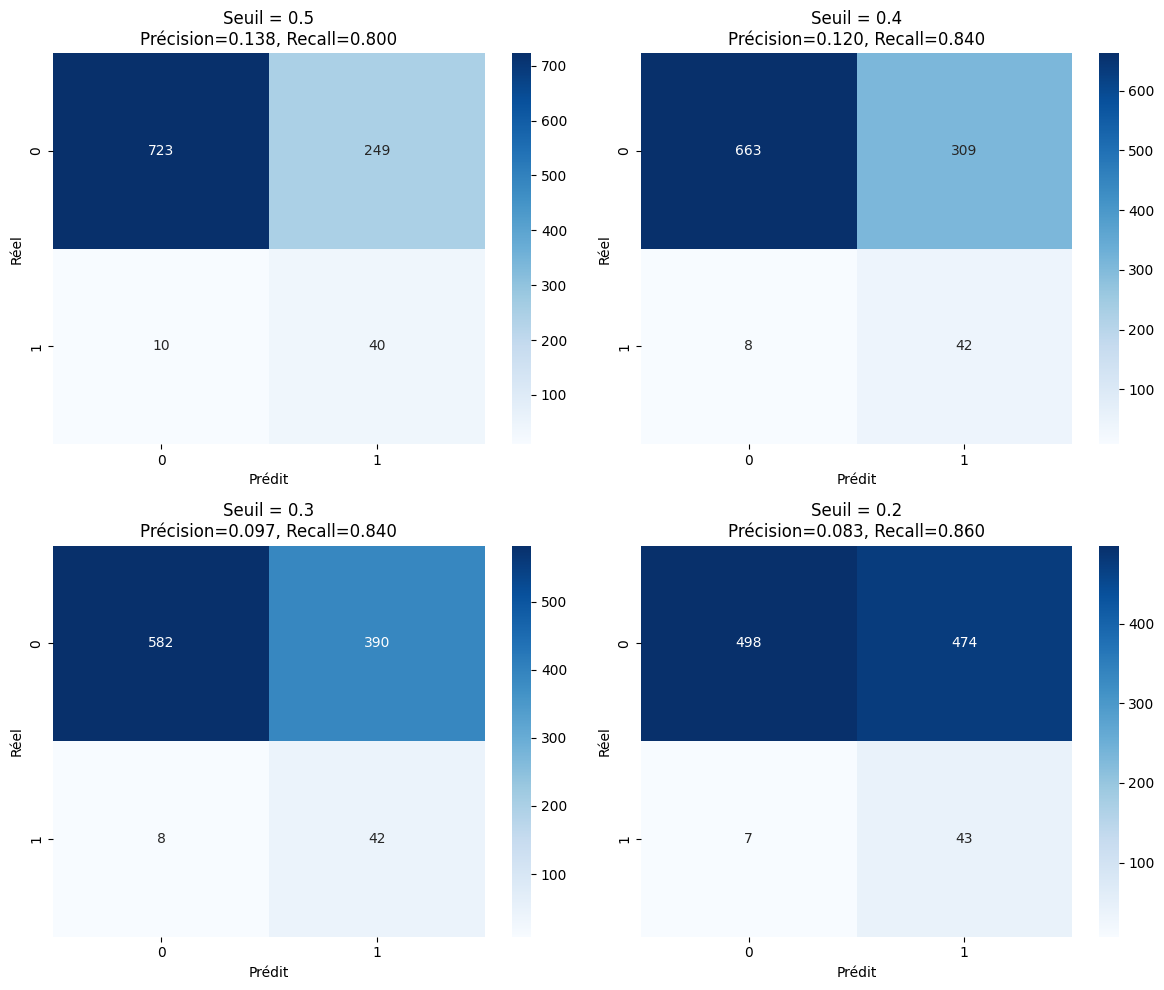


💡 INTERPRÉTATION :
- Seuil 0.5 : Équilibre standard
- Seuil 0.4 : Meilleur compromis pour le contexte médical
- Seuil 0.3 : Plus sensible, plus de faux positifs
- Seuil 0.2 : Très sensible, beaucoup de faux positifs


In [11]:
# 09. Analyse des seuils
print("="*60)
print("🎯 ANALYSE DES SEUILS DE DÉCISION")
print("="*60)

y_proba_best = results[best_name]['y_proba']

thresholds = [0.5, 0.4, 0.3, 0.2]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

print("\n📊 Résultats par seuil :")
print("-"*60)
print(f"{'Seuil':<8} {'Précision':<12} {'Recall':<12} {'F1':<10} {'TP':<6} {'FN':<6}")
print("-"*60)

for idx, thresh in enumerate(thresholds):
    y_pred_th = (y_proba_best >= thresh).astype(int)
    cm = confusion_matrix(y_test, y_pred_th)
    tn, fp, fn, tp = cm.ravel()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    print(f"{thresh:<8.1f} {precision:<12.4f} {recall:<12.4f} {f1:<10.4f} {tp:<6} {fn:<6}")

    ax = axes[idx // 2, idx % 2]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(f'Seuil = {thresh}\nPrécision={precision:.3f}, Recall={recall:.3f}')
    ax.set_xlabel('Prédit')
    ax.set_ylabel('Réel')

plt.tight_layout()
plt.show()

print("\n💡 INTERPRÉTATION :")
print("- Seuil 0.5 : Équilibre standard")
print("- Seuil 0.4 : Meilleur compromis pour le contexte médical")
print("- Seuil 0.3 : Plus sensible, plus de faux positifs")
print("- Seuil 0.2 : Très sensible, beaucoup de faux positifs")

In [12]:
# 10. Conclusion
print("="*60)
print("📝 CONCLUSION")
print("="*60)

print(f"\n✅ Meilleur modèle : {best_name}")
print(f"   - ROC-AUC: {results[best_name]['roc_auc']:.4f}")
print(f"   - Recall: {results[best_name]['recall']:.4f}")
print(f"   - F1-Score: {results[best_name]['f1']:.4f}")

print("\n🔍 Principaux facteurs de risque identifiés :")
print("   1. Âge (facteur le plus important)")
print("   2. Glycémie élevée")
print("   3. Hypertension")
print("   4. Maladie cardiaque")

print("\n⚠️ Limites :")
print("   - Données déclaratives (tabagisme auto-déclaré)")
print("   - Imputation du BMI (3.9% des données)")
print("   - Absence de validation externe")
print("   - Modèle pédagogique, non utilisable en clinique")

print("\n🚀 Pistes d'amélioration :")
print("   - Intégrer des données de suivi médical")
print("   - Tester XGBoost ou LightGBM")
print("   - Valider sur une cohorte externe")

print("\n🩺 Discussion éthique :")
print("   Ce modèle est un outil pédagogique. Il ne remplace pas")
print("   un diagnostic médical. Toute décision clinique doit")
print("   rester entre les mains d'un professionnel de santé.")

📝 CONCLUSION

✅ Meilleur modèle : Logistic Regression
   - ROC-AUC: 0.8441
   - Recall: 0.8000
   - F1-Score: 0.2360

🔍 Principaux facteurs de risque identifiés :
   1. Âge (facteur le plus important)
   2. Glycémie élevée
   3. Hypertension
   4. Maladie cardiaque

⚠️ Limites :
   - Données déclaratives (tabagisme auto-déclaré)
   - Imputation du BMI (3.9% des données)
   - Absence de validation externe
   - Modèle pédagogique, non utilisable en clinique

🚀 Pistes d'amélioration :
   - Intégrer des données de suivi médical
   - Tester XGBoost ou LightGBM
   - Valider sur une cohorte externe

🩺 Discussion éthique :
   Ce modèle est un outil pédagogique. Il ne remplace pas
   un diagnostic médical. Toute décision clinique doit
   rester entre les mains d'un professionnel de santé.
